# Phase 6: Injury profiles per style (what kind of injuries, not how many)

**Question:** does a playing style change *which* injuries its players get (tissue type, body location, severity)?
Phase 5 asked *how many*, and the answer was mostly schedule and team strength. Comparing the **mix** of a style's
injuries with the mix expected for the same leagues and seasons largely cancels exposure, team strength (as a volume
effect) and Transfermarkt's under-reporting, which act on all injury kinds alike.

**Research questions (fixed 2026-10-25, before the results):**
- **RQ-P1:** does the injury mix differ between attacking styles, and between defensive styles? One omnibus
  permutation test per family: type, location, type × location pattern, severity.
- **RQ-P2:** which style × injury-category patterns? **Profile ratio** = observed ÷ expected injuries of a category,
  expected from the league × season mix (main), then + position, then + team strength; 95% CI over clubs;
  permutation test; Benjamini–Hochberg over all tests; q < 0.05 is a finding.
- **RQ-P3:** do team-seasons form groups by injury profile (a second clustering), and do those groups line up with the
  style clusters? Compared with a no-structure null; Cramér's V and ARI with styles, strength and league.

**Categories** (Phase 2 label map): type (muscle, ligament/joint, impact, fracture/bone, tendon, other; *unspecified*
left out of the type shares); location (the 8 commonest known body areas; *unspecified muscle* counts as unknown
location); patterns (type × location with at least 300 injuries); severity (severe, > 28 days).

**Steps**
1. Injuries with their team's styles and categories
2. Expected mix (indirect standardisation) and team-season totals
3. RQ-P1: does the mix differ by style? (omnibus permutation tests)
4. RQ-P2: profile ratios per style and category
5. Injury-profile features per team-season
6. RQ-P3: clustering team-seasons by injury profile
7. RQ-P3: do the injury-profile groups line up with styles?
8. Report

**Inputs:** `data/02_injuries/injuries_clean.parquet`, `data/05_injury_analysis/player_seasons.parquet`.
**Outputs:** `data/06_injury_profiles/`, `reports/06_injury_profiles.md`, `reports/figures/06_*.png`.

In [1]:
import sys
import zlib
from datetime import date
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2_contingency
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

sys.path.insert(0, str(Path.cwd().parent))  # project root, for the analysis package
from analysis.config import DATA_DIR, FIGURES_DIR, REPORTS_DIR, phase_dir
from analysis.report import md_table

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)

PHASE = "06_injury_profiles"
OUT_DIR = phase_dir(PHASE)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
N_BOOT = 1000  # club bootstrap for profile-ratio CIs
N_PERM = 10_000  # permutation tests
MIN_PATTERN = 300  # a type × location pattern is tested when it has at least this many injuries
ATTACK = ["Positional possession", "Build-up into the box", "Counter-attack", "Direct play"]
DEFENCE = ["High press, high line", "Compact mid-block", "Aggressive duel press", "Low block"]
PHASES = {"attack": ("attack_style", ATTACK), "defence": ("defence_style", DEFENCE)}
TYPES = ["muscle", "ligament/joint", "impact", "fracture/bone", "tendon", "other"]

INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
    "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
})


def save(fig, name: str) -> str:
    path = FIGURES_DIR / name
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(path)))
    return name

## Step 1. Injuries with their team's styles and categories

Each injury > 7 days gets its player-club-season's league, season, era, club, team-season, attacking and defensive
style, team strength third and the player's position (Phase 5 table), and its category indicators.

In [2]:
ps = pd.read_parquet(DATA_DIR / "05_injury_analysis" / "player_seasons.parquet")
injuries = pd.read_parquet(DATA_DIR / "02_injuries" / "injuries_clean.parquet")
KEY = ["playerId", "club_id", "season"]
inj = injuries.drop(columns=["league"]).merge(
    ps[KEY + ["league", "era", "team_season", "attack_style", "defence_style", "strength", "position"]], on=KEY, how="left")
inj["strength"] = inj.strength.astype(str)
inj["location"] = inj.body_area.replace({"unspecified muscle": "unknown"})
LOCATIONS = inj.loc[inj.location != "unknown", "location"].value_counts().index[:8].tolist()
inj["pattern"] = inj.injury_type + " · " + inj.location
pattern_counts = inj[(inj.injury_type != "unspecified") & (inj.location != "unknown")].pattern.value_counts()
PATTERNS = pattern_counts[pattern_counts >= MIN_PATTERN].index.tolist()
inj["severe"] = inj.severity.str.startswith("severe")

# Category indicators Y (1 = this injury is of the category) and denominators D (1 = the injury counts in the share).
FAMILIES = {"type": TYPES, "location": LOCATIONS, "pattern": PATTERNS, "severity": ["severe"]}
known_type = (inj.injury_type != "unspecified").to_numpy()
known_loc = (inj.location != "unknown").to_numpy()
cats, Y, D = [], [], []
for fam, values in FAMILIES.items():
    for v in values:
        cats.append((fam, v))
        if fam == "type":
            Y.append(inj.injury_type.eq(v).to_numpy()), D.append(known_type)
        elif fam == "location":
            Y.append(inj.location.eq(v).to_numpy()), D.append(known_loc)
        elif fam == "pattern":
            Y.append(inj.pattern.eq(v).to_numpy()), D.append(np.ones(len(inj), bool))
        else:
            Y.append(inj.severe.to_numpy()), D.append(np.ones(len(inj), bool))
CATS = pd.MultiIndex.from_tuples(cats, names=["family", "category"])
Y = pd.DataFrame(np.column_stack(Y).astype(float), columns=CATS, index=inj.index)
D = pd.DataFrame(np.column_stack(D).astype(float), columns=CATS, index=inj.index)

assert len(inj) == len(injuries) and inj.team_season.notna().all() and inj.position.notna().all()
assert ((Y <= D).all()).all()
pd.concat({"injuries in the category": Y.sum().astype(int), "share of its denominator": (Y.sum() / D.sum()).round(3)}, axis=1)

injuries in the category  share of its denominator
family   category                                                                            
type     muscle                                               11418                     0.662
         ligament/joint                                        2138                     0.124
         impact                                                1805                     0.105
         fracture/bone                                          842                     0.049
         tendon                                                 562                     0.033
         other                                                  493                     0.029
location knee                                                  3624                     0.212
         hamstring                                             3249                     0.190
         groin/adductor/hip                                    2305                     0.135
         ankle                                                 2155                     0.126
         calf/achilles/lower leg                               1882                     0.110
         thigh                                                 1069                     0.063
         upper body                                            1023                     0.060
         foot/toe                                               837                     0.049
pattern  muscle · hamstring                                    3244                     0.132
         muscle · groin/adductor/hip                           1676                     0.068
         muscle · calf/achilles/lower leg                      1350                     0.055
         ligament/joint · knee                                 1246                     0.051
         muscle · thigh                                         723                     0.029
         ligament/joint · ankle                                 566                     0.023
         impact · thigh                                         342                     0.014
         tendon · calf/achilles/lower leg                       326                     0.013
severity severe                                               10989                     0.448

## Step 2. Expected mix (indirect standardisation) and team-season totals

For each injury and category, the expected probability is the category's share among the injuries of the same
**stratum**: league × season (main), + position, + position and team strength. A team-season's expected count is the
sum over its injuries, so a style's **profile ratio** = observed ÷ expected tells whether its injuries lean to that
category more than injuries in the same leagues and seasons (1 = same mix).

In [3]:
STRATA = {"main": ["league", "season"], "pos": ["league", "season", "position"],
          "pos_str": ["league", "season", "position", "strength"]}


def expected(strata: list[str]) -> pd.DataFrame:
    keys = [inj[c] for c in strata]
    share = (Y.groupby(keys).transform("sum") / D.groupby(keys).transform("sum")).fillna(0)
    return share * D


E = {name: expected(s) for name, s in STRATA.items()}
TEAM = inj.groupby("team_season").agg(league=("league", "first"), season=("season", "first"), club_id=("club_id", "first"),
                                      attack_style=("attack_style", "first"), defence_style=("defence_style", "first"),
                                      strength=("strength", "first"), era=("era", "first"), injuries=("days", "size"))
O_ts = Y.groupby(inj.team_season).sum().loc[TEAM.index]
D_ts = D.groupby(inj.team_season).sum().loc[TEAM.index]
E_ts = {name: e.groupby(inj.team_season).sum().loc[TEAM.index] for name, e in E.items()}

for name, e in E_ts.items():
    assert np.allclose(e.sum(), O_ts.sum()), name  # expected totals equal observed totals over all injuries
print(len(TEAM), "team-seasons with at least one injury;", int(TEAM.injuries.sum()), "injuries")
E_ts["main"].sum().round(1).head()

1170 team-seasons with at least one injury; 24555 injuries


family  category      
type    muscle            11418.0
        ligament/joint     2138.0
        impact             1805.0
        fracture/bone       842.0
        tendon              562.0
dtype: float64

## Step 3. RQ-P1: does the mix differ by style? (omnibus permutation tests)

For each phase of play and family: T = Σ over styles and categories of (O − E)² / E. Under "style does not change the
mix", style labels are exchangeable among team-seasons of the same league-season, so the labels are shuffled within
league-seasons 10,000 times (seed 42) and T is recomputed; p = share of shuffles with T at least as large. Shuffling
whole team-seasons keeps a squad's injuries together. Effect size: V = √(T / (N × (min(styles, categories) − 1))),
read like Cramér's V. The same shuffles serve Step 4.

In [4]:
rng = np.random.default_rng(SEED)
groups = list(TEAM.reset_index().groupby(["league", "season"]).indices.values())
perm_idx = np.tile(np.arange(len(TEAM), dtype=np.int32), (N_PERM, 1))
for b in range(N_PERM):
    for g in groups:
        perm_idx[b, g] = rng.permutation(g)

O_arr, E_arr, D_arr = O_ts.to_numpy(), E_ts["main"].to_numpy(), D_ts.to_numpy()
EXCESS = O_arr - E_arr
perm_member = {ph: np.stack([TEAM[col].to_numpy()[perm_idx] == s for s in styles], axis=1)  # (shuffle × style × team-season)
               for ph, (col, styles) in PHASES.items()}


def perm_sums(member: np.ndarray, values: np.ndarray, chunk: int = 1000) -> np.ndarray:
    """Σ values over each style's team-seasons, for every shuffle: (shuffle × style × column)."""
    return np.concatenate([member[i:i + chunk].astype(np.float32) @ values.astype(np.float32)
                           for i in range(0, len(member), chunk)])


def family_arrays(fam: str) -> tuple[np.ndarray, np.ndarray]:
    """Observed and expected per team-season for a family's categories plus 'the rest' of its denominator."""
    cols = [i for i, (f, _) in enumerate(cats) if f == fam]
    denom = D_arr[:, cols[0]]
    o = np.column_stack([O_arr[:, cols], denom - O_arr[:, cols].sum(axis=1)])
    e = np.column_stack([E_arr[:, cols], denom - E_arr[:, cols].sum(axis=1)])
    return o, e


def t_stat(oo: np.ndarray, ee: np.ndarray) -> np.ndarray:
    return np.where(ee > 0, (oo - ee) ** 2 / np.where(ee > 0, ee, 1), 0).sum(axis=(-2, -1))


omnibus_rows = []
for ph, (col, styles) in PHASES.items():
    member = np.stack([TEAM[col].to_numpy() == s for s in styles]).astype(float)
    for fam in FAMILIES:
        o, e = family_arrays(fam)
        observed = float(t_stat(member @ o, member @ e))
        shuffled = t_stat(perm_sums(perm_member[ph], o), perm_sums(perm_member[ph], e))
        n = float(o.sum())
        n_cat = o.shape[1] - int(np.allclose(o[:, -1], 0))  # 'the rest' is empty for types (they cover every known type)
        omnibus_rows.append({"phase": ph, "family": fam, "categories": n_cat, "injuries": int(n), "T": observed,
                             "shuffled T (median)": float(np.median(shuffled)),
                             "p": (1 + (shuffled >= observed).sum()) / (N_PERM + 1),
                             "V": np.sqrt(observed / (n * (min(len(styles), n_cat) - 1)))})
omnibus = pd.DataFrame(omnibus_rows)
assert len(omnibus) == 8 and omnibus.p.between(0, 1).all()
omnibus.round(4)

,phase,family,categories,injuries,T,shuffled T (median),p,V
0,attack,type,6,17258,27.4435,16.2835,0.0672,0.0230
1,attack,location,9,17056,47.9446,26.4394,0.0129,0.0306
2,attack,pattern,9,24555,94.3046,29.6504,0.0001,0.0358
3,attack,severity,2,24555,96.9510,3.3699,0.0001,0.0628
4,defence,type,6,17258,29.2899,14.8077,0.0251,0.0238
5,defence,location,9,17056,65.7283,24.0408,0.0001,0.0358
6,defence,pattern,9,24555,103.0452,27.6655,0.0001,0.0374
7,defence,severity,2,24555,91.2369,3.0430,0.0001,0.0610


## Step 4. RQ-P2: profile ratios per style and category

Profile ratio = Σ observed ÷ Σ expected over the style's team-seasons; 95% CI from 1,000 bootstrap resamples of
**clubs** (seed from the table name); permutation p from the shuffles of Step 3 (two-sided, on observed − expected);
Benjamini–Hochberg over all style × category tests. A finding needs q < 0.05; it is **robust** when, with position
and team strength added to the expected mix, the ratio's 95% CI (same club bootstrap) still excludes 1 on the same side.

In [5]:
def benjamini_hochberg(p: pd.Series) -> pd.Series:
    order = p.sort_values()
    q = (order * len(p) / np.arange(1, len(p) + 1)).iloc[::-1].cummin().iloc[::-1].clip(upper=1)
    return q.reindex(p.index)


clubs = TEAM.club_id.to_numpy()
club_codes, club_index = np.unique(clubs, return_inverse=True)
boot_rng = np.random.default_rng([SEED, zlib.crc32(b"profile_ratios")])
boot_w = np.stack([np.bincount(boot_rng.integers(0, len(club_codes), len(club_codes)), minlength=len(club_codes))
                   for _ in range(N_BOOT)])[:, club_index].astype(np.float32)  # (boot × team-season) weights

rows = []
for ph, (col, styles) in PHASES.items():
    labels = TEAM[col].to_numpy()
    for si, style in enumerate(styles):
        member = labels == style
        o, e = O_arr[member].sum(axis=0), E_arr[member].sum(axis=0)
        bo, be = boot_w[:, member] @ O_arr[member], boot_w[:, member] @ E_arr[member]
        lo, hi = np.nanpercentile(bo / be, [2.5, 97.5], axis=0)
        shuffled = perm_sums(perm_member[ph][:, si:si + 1, :], EXCESS)[:, 0, :]
        p = (1 + (np.abs(shuffled) >= np.abs(o - e)).sum(axis=0)) / (N_PERM + 1)
        adj = {name: O_arr[member].sum(axis=0) / E_ts[name].to_numpy()[member].sum(axis=0) for name in ["pos", "pos_str"]}
        e_adj = E_ts["pos_str"].to_numpy()[member]
        lo_adj, hi_adj = np.nanpercentile(bo / (boot_w[:, member] @ e_adj), [2.5, 97.5], axis=0)
        for ci, (fam, cat) in enumerate(cats):
            rows.append({"phase": ph, "style": style, "family": fam, "category": cat, "observed": int(o[ci]),
                         "expected": e[ci], "ratio": o[ci] / e[ci], "low": lo[ci], "high": hi[ci], "p": p[ci],
                         "ratio + position": adj["pos"][ci], "ratio + position + strength": adj["pos_str"][ci],
                         "adjusted low": lo_adj[ci], "adjusted high": hi_adj[ci]})
profiles = pd.DataFrame(rows)
profiles["q (BH)"] = benjamini_hochberg(profiles.p)
profiles["robust"] = np.where(profiles.ratio > 1, profiles["adjusted low"] > 1, profiles["adjusted high"] < 1)
profiles["finding"] = profiles["q (BH)"] < 0.05
findings = profiles[profiles.finding].sort_values(["phase", "style", "ratio"])

assert len(profiles) == 8 * len(cats) and profiles.ratio.notna().all()
print(f"{len(profiles)} tests; {int(profiles.finding.sum())} findings (q < 0.05), {int((profiles.finding & profiles.robust).sum())} robust")
findings[["phase", "style", "family", "category", "observed", "expected", "ratio", "low", "high", "q (BH)",
          "ratio + position + strength", "adjusted low", "adjusted high", "robust"]].round(3)

184 tests; 18 findings (q < 0.05), 1 robust


,phase,style,family,category,observed,expected,ratio,low,high,q (BH),ratio + position + strength,adjusted low,adjusted high,robust
43,attack,Build-up into the box,pattern,impact · thigh,77,123.484,0.624,0.403,0.888,0.003,0.713,0.500,0.993,True
68,attack,Counter-attack,severity,severe,2421,2291.164,1.057,1.023,1.086,0.008,1.005,0.979,1.029,False
66,attack,Counter-attack,pattern,impact · thigh,79,46.982,1.682,1.094,2.164,0.006,1.342,0.916,1.707,False
84,attack,Direct play,pattern,muscle · groin/adductor/hip,462,519.602,0.889,0.805,0.975,0.044,0.960,0.876,1.037,False
91,attack,Direct play,severity,severe,3363,3172.871,1.060,1.030,1.089,0.003,1.012,0.984,1.042,False
22,attack,Positional possession,severity,severe,1825,2090.647,0.873,0.826,0.918,0.003,0.955,0.905,1.001,False
160,defence,Aggressive duel press,severity,severe,2630,2463.418,1.068,1.024,1.113,0.003,1.036,0.998,1.074,False
139,defence,Aggressive duel press,type,ligament/joint,588,536.464,1.096,1.013,1.177,0.038,1.064,0.992,1.136,False
137,defence,Compact mid-block,severity,severe,2413,2562.468,0.942,0.899,0.987,0.005,0.983,0.947,1.020,False
114,defence,"High press, high line",severity,severe,2426,2644.039,0.918,0.875,0.966,0.003,0.976,0.937,1.016,False


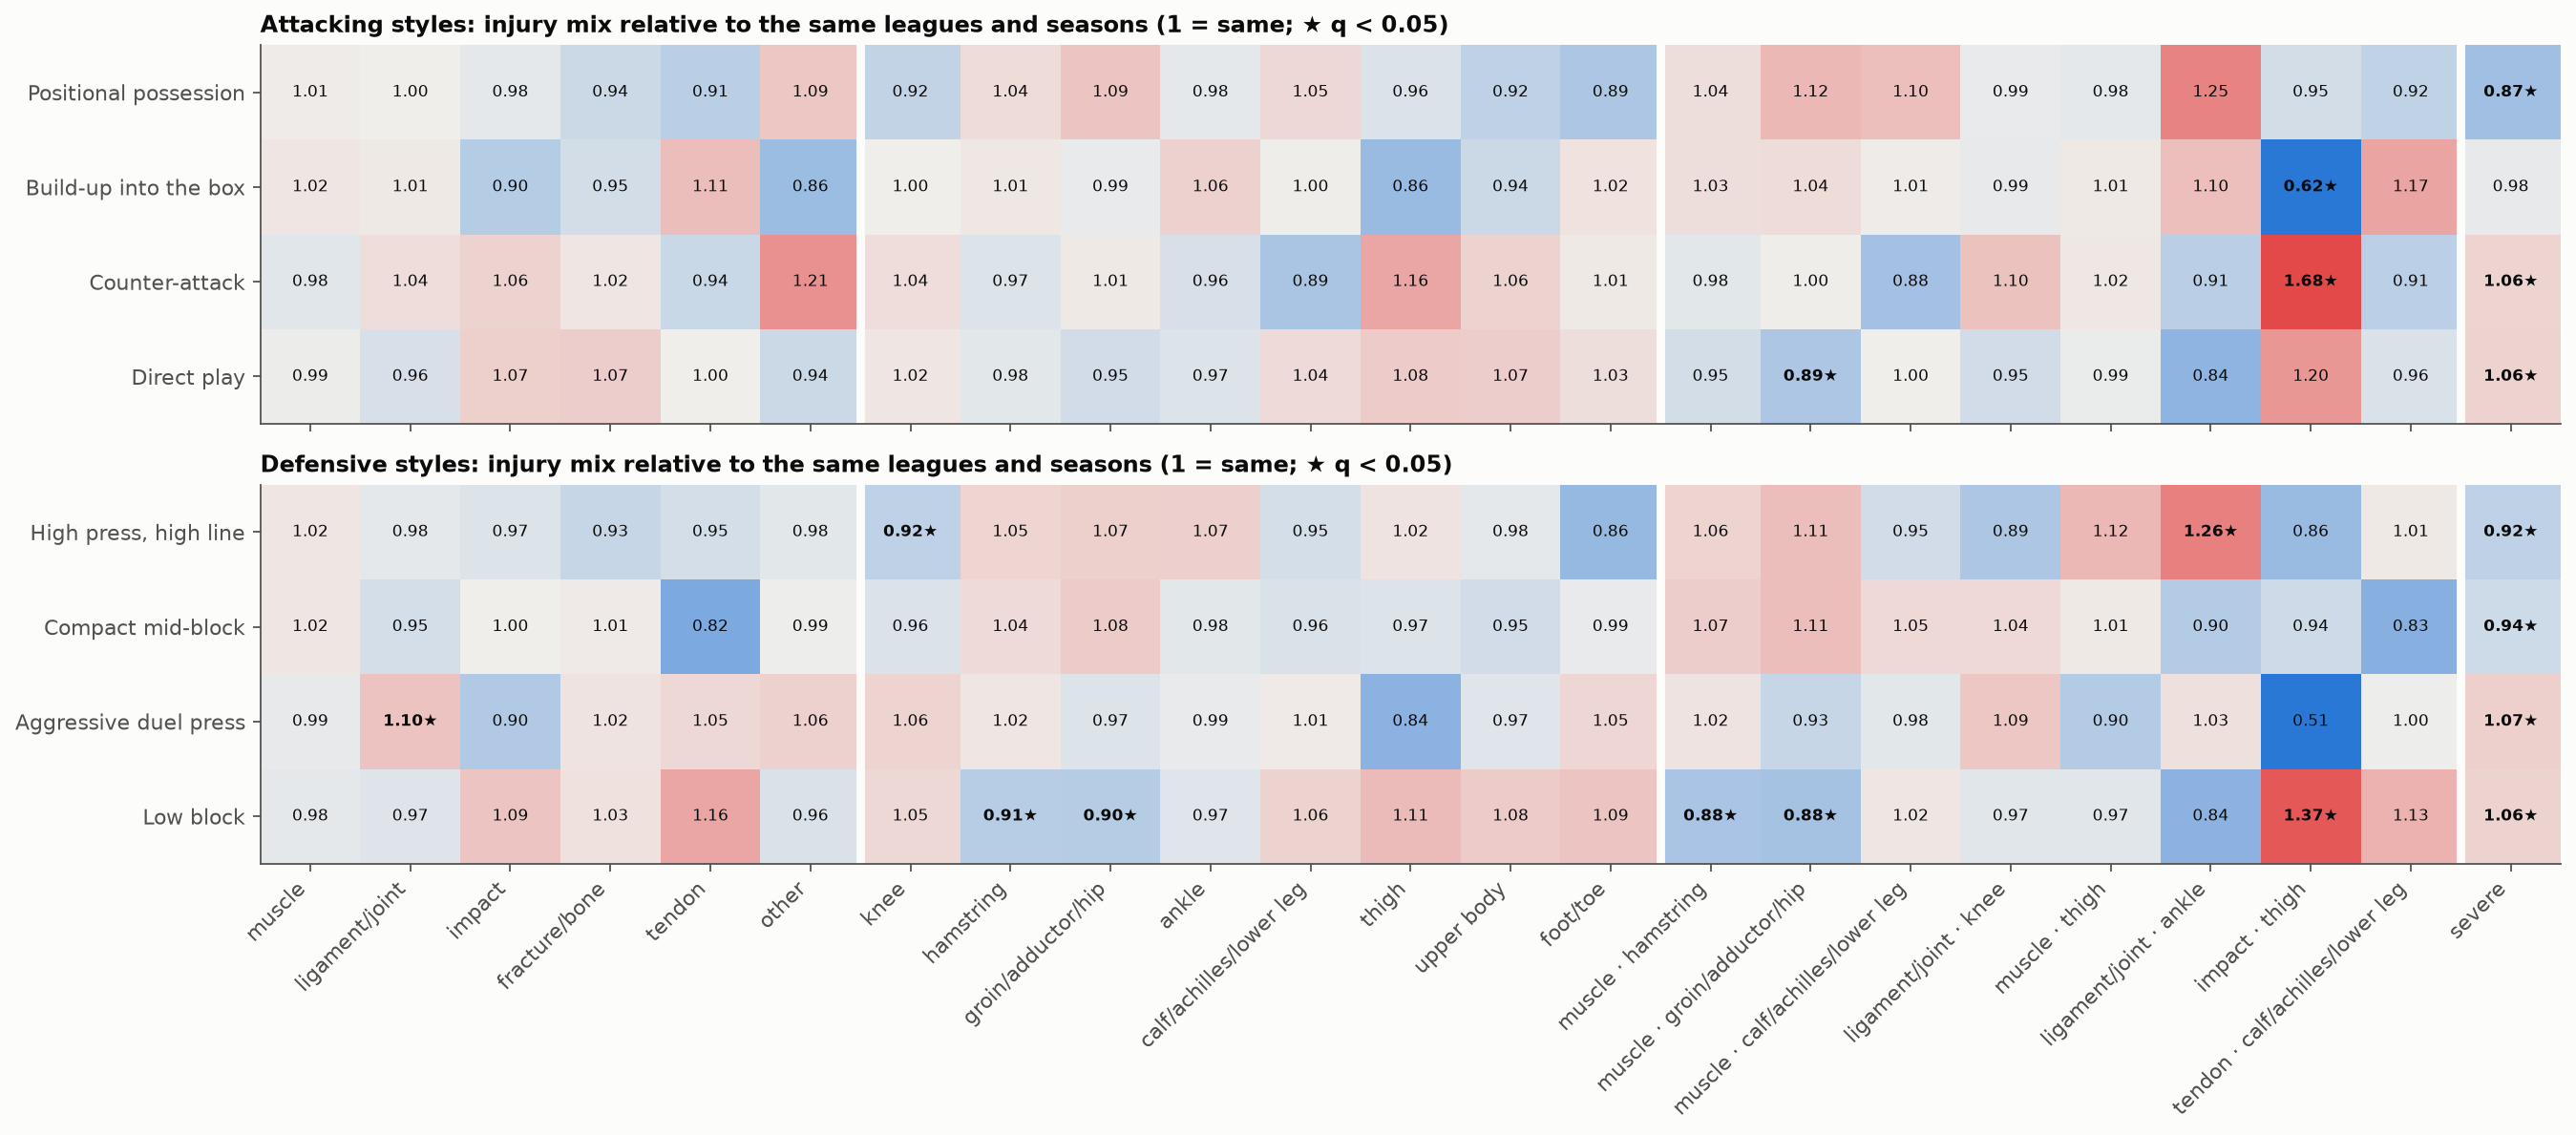

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(17, 7.6))
labels_x = [f"{c}" for _, c in cats]
for ax, (ph, (col, styles)) in zip(axes, PHASES.items()):
    t = profiles[profiles.phase == ph]
    mat = t.pivot_table(index="style", columns=["family", "category"], values="ratio", sort=False).reindex(index=styles)[CATS]
    q = t.pivot_table(index="style", columns=["family", "category"], values="q (BH)", sort=False).reindex(index=styles)[CATS]
    ax.imshow(np.log2(mat.to_numpy(dtype=float)), cmap=DIVERGING, vmin=-0.5, vmax=0.5, aspect="auto")
    ax.set_yticks(range(len(styles)), styles)
    ax.set_xticks(range(len(cats)), labels_x if ph == "defence" else [""] * len(cats), rotation=45, ha="right")
    for (i, j), v in np.ndenumerate(mat.to_numpy(dtype=float)):
        star = "★" if q.to_numpy()[i, j] < 0.05 else ""
        ax.text(j, i, f"{v:.2f}{star}", ha="center", va="center", fontsize=7.5, color=INK,
                fontweight="bold" if star else "normal")
    edges = np.cumsum([len(v) for v in FAMILIES.values()])[:-1] - 0.5
    for x in edges:
        ax.axvline(x, color=SURFACE, linewidth=4)
    ax.set_title(f"{'Attacking' if ph == 'attack' else 'Defensive'} styles: injury mix relative to the same leagues and seasons "
                 "(1 = same; ★ q < 0.05)", loc="left")
fig.tight_layout()
profile_fig = save(fig, "06_profile_ratios.png")

## Step 5. Injury-profile features per team-season

For the second clustering each team-season (with at least 10 injuries, fixed in advance) is described by how its
injury mix departs from its league-season's mix: for the 5 main types, the 6 commonest locations and the severe
share, the **smoothed** share (observed + 10 × league-season share) ÷ (denominator + 10) minus the league-season
share. Smoothing with 10 pseudo-injuries pulls small, noisy team-seasons towards their league-season, so a team with
12 injuries is not called "a hamstring team" on 4 hamstrings. Each feature is then standardised.

In [7]:
MIN_INJ = 10
ALPHA = 10
FEATS = [("type", t) for t in TYPES[:5]] + [("location", l) for l in LOCATIONS[:6]] + [("severity", "severe")]
keep = TEAM.injuries >= MIN_INJ
o, d = O_ts.loc[keep, FEATS], D_ts.loc[keep, FEATS]
ls_share = (O_ts[FEATS].groupby([TEAM.league, TEAM.season]).transform("sum")
            / D_ts[FEATS].groupby([TEAM.league, TEAM.season]).transform("sum")).loc[keep]
dev = (o + ALPHA * ls_share) / (d + ALPHA) - ls_share
dev.columns = [c for _, c in FEATS]
Z = (dev - dev.mean()) / dev.std()
X = Z.to_numpy()

assert not np.isnan(X).any() and len(Z) == keep.sum()
print(f"{int(keep.sum())} of {len(TEAM)} team-seasons with ≥ {MIN_INJ} injuries")
dev.describe().T[["mean", "std", "min", "max"]].round(3)

1023 of 1170 team-seasons with ≥ 10 injuries


,mean,std,min,max
muscle,-0.001,0.080,-0.273,0.275
ligament/joint,-0.000,0.051,-0.138,0.180
impact,0.001,0.060,-0.206,0.301
fracture/bone,0.000,0.035,-0.060,0.215
tendon,0.001,0.030,-0.067,0.171
knee,0.000,0.069,-0.164,0.252
hamstring,-0.001,0.065,-0.174,0.278
groin/adductor/hip,-0.002,0.055,-0.115,0.188
ankle,0.001,0.055,-0.111,0.217
calf/achilles/lower leg,0.000,0.052,-0.107,0.251


## Step 6. RQ-P3: clustering team-seasons by injury profile

K-means (50 starts, seed 42) for k = 2…8, with the Phase 4 criteria: silhouette, bootstrap stability (50 resamples:
mean ARI and the weakest cluster's Jaccard), and the rule that every cluster keeps a Jaccard ≥ 0.6 and ≥ 3% of
team-seasons. A **null** shows what "no structure" looks like: each feature shuffled independently within
league-seasons (20 times), which keeps every feature's spread but breaks the links between them. Real injury-profile
groups need a silhouette clearly above the null's. k is the usable k with the highest silhouette; if none is usable,
there are no stable injury-profile groups and k = 2 is described only for illustration.

In [8]:
K_RANGE = range(2, 9)
N_BOOT_CL, N_NULL, N_INIT = 50, 20, 50
cl_rng = np.random.default_rng([SEED, zlib.crc32(b"profile_clusters")])
boot_idx = [cl_rng.integers(0, len(X), len(X)) for _ in range(N_BOOT_CL)]
ls_groups = list(Z.reset_index(drop=True).groupby([TEAM.loc[keep, "league"].to_numpy(), TEAM.loc[keep, "season"].to_numpy()]).indices.values())


def null_data(r: np.random.Generator) -> np.ndarray:
    xn = X.copy()
    for j in range(X.shape[1]):
        for g in ls_groups:
            xn[g, j] = X[r.permutation(g), j]
    return xn


nulls = [null_data(cl_rng) for _ in range(N_NULL)]
k_rows, fits = [], {}
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(X)
    fits[k] = km
    aris, jac = [], np.zeros((N_BOOT_CL, k))
    for b, idx in enumerate(boot_idx):
        fit = KMeans(n_clusters=k, n_init=10, random_state=SEED + b).fit(X[idx])
        aris.append(adjusted_rand_score(km.labels_, fit.predict(X)))
        inside = np.unique(idx)
        both = np.zeros((k, k))
        np.add.at(both, (km.labels_[inside], fit.predict(X[inside])), 1)
        jac[b] = (both / (both.sum(axis=1, keepdims=True) + both.sum(axis=0, keepdims=True) - both)).max(axis=1)
    null_sil = [silhouette_score(xn, KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(xn)) for xn in nulls]
    k_rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X, km.labels_),
                   "null silhouette (mean)": np.mean(null_sil), "null silhouette (95th pct)": np.percentile(null_sil, 95),
                   "stability (mean ARI)": np.mean(aris), "min cluster Jaccard": jac.mean(axis=0).min(),
                   "smallest cluster": int(np.bincount(km.labels_).min())})
k_table = pd.DataFrame(k_rows).set_index("k")
k_table["above null"] = k_table.silhouette > k_table["null silhouette (95th pct)"]
k_table["usable"] = (k_table["min cluster Jaccard"] >= 0.6) & (k_table["smallest cluster"] >= 0.03 * len(X))
usable = k_table[k_table.usable]
K = int(usable.silhouette.idxmax()) if len(usable) else 2
groups_found = bool(len(usable)) and bool(k_table.loc[K, "above null"])
print(f"chosen k = {K}; usable k: {list(usable.index)}; stable groups above the null: {groups_found}")
k_table.round(3)

chosen k = 2; usable k: [2, 3, 4]; stable groups above the null: True


,inertia,silhouette,null silhouette (mean),null silhouette (95th pct),stability (mean ARI),min cluster Jaccard,smallest cluster,above null,usable
k,,,,,,,,,
2,10795.852,0.117,0.068,0.073,0.791,0.880,432,True,True
3,10008.365,0.104,0.065,0.070,0.639,0.641,303,True,True
4,9377.137,0.104,0.065,0.071,0.634,0.641,176,True,True
5,8887.048,0.097,0.068,0.072,0.476,0.447,132,True,False
6,8454.466,0.103,0.069,0.073,0.517,0.535,113,True,False
7,8111.574,0.102,0.071,0.076,0.515,0.420,98,True,False
8,7809.156,0.098,0.071,0.080,0.515,0.460,93,True,False


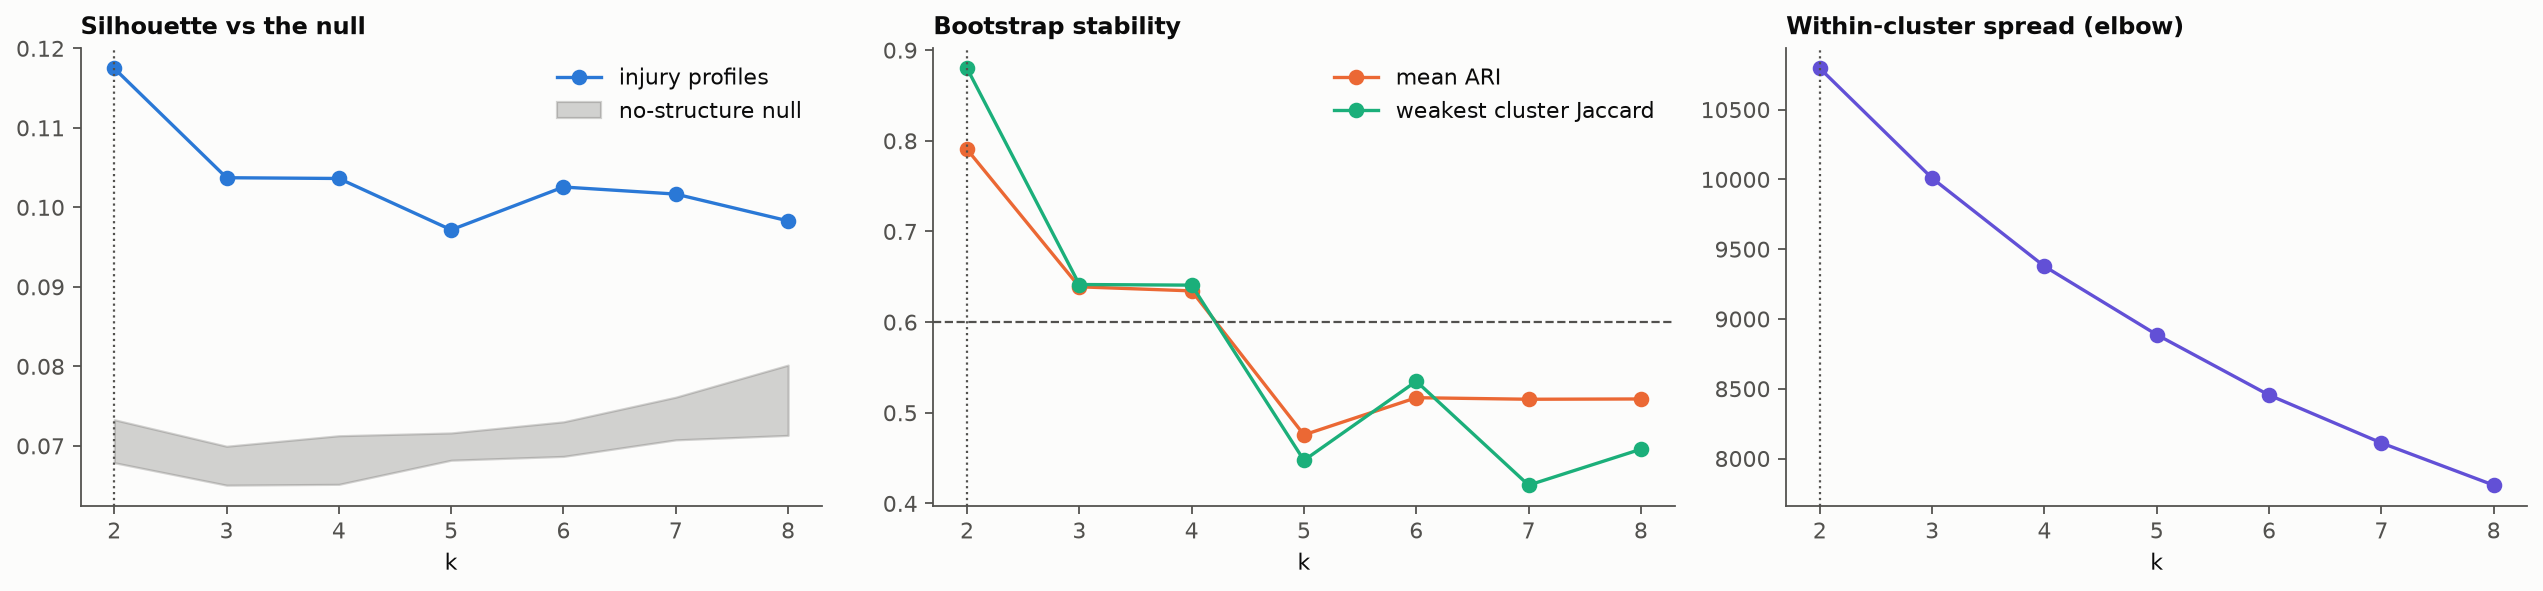

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
ks = list(K_RANGE)
axes[0].plot(ks, k_table.silhouette, marker="o", color=SERIES[0], label="injury profiles")
axes[0].fill_between(ks, k_table["null silhouette (mean)"], k_table["null silhouette (95th pct)"], color=MUTED, alpha=0.25, label="no-structure null")
axes[0].set_title("Silhouette vs the null", loc="left")
axes[0].legend(frameon=False)
axes[1].plot(ks, k_table["stability (mean ARI)"], marker="o", color=SERIES[1], label="mean ARI")
axes[1].plot(ks, k_table["min cluster Jaccard"], marker="o", color=SERIES[2], label="weakest cluster Jaccard")
axes[1].axhline(0.6, color=MUTED, linestyle="--", linewidth=1)
axes[1].set_title("Bootstrap stability", loc="left")
axes[1].legend(frameon=False)
axes[2].plot(ks, k_table.inertia, marker="o", color=SERIES[6])
axes[2].set_title("Within-cluster spread (elbow)", loc="left")
for ax in axes:
    ax.axvline(K, color=MUTED, linestyle=":", linewidth=1)
    ax.set_xlabel("k")
fig.tight_layout()
k_fig = save(fig, "06_profile_k.png")

## Step 7. RQ-P3: do the injury-profile groups line up with styles?

Each group is named after the features its centre is clearly above average on (z ≥ 0.4), else "average mix". The
groups are then cross-tabulated with attacking style, defensive style, team strength, league and era. Cramér's V and
ARI measure agreement; for the styles a permutation p (style labels shuffled within league-seasons, 10,000 times)
tells whether the agreement beats chance, and a second one shuffles within league-season × strength third, so a
style only gets credit for what team strength does not already explain. League and era show whether the groups are recording habits rather than
football.

In [10]:
labels = fits[K].labels_
centres = pd.DataFrame(fits[K].cluster_centers_, columns=Z.columns)


def group_name(row: pd.Series) -> str:
    up = row[row >= 0.4].sort_values(ascending=False).index[:2].tolist()
    down = row[row <= -0.4].sort_values().index[:1].tolist()
    if not up and not down:
        return "average mix"
    return " & ".join(f"more {u}" for u in up) + (", " if up and down else "") + (f"less {down[0]}" if down else "")


names = {i: f"P{i + 1}: {group_name(r)}" for i, r in centres.iterrows()}
prof = TEAM.loc[keep].assign(profile=[names[l] for l in labels])
centres.index = [names[i] for i in centres.index]


def cramers_v(a: pd.Series, b: pd.Series) -> float:
    table = pd.crosstab(a, b)
    return float(np.sqrt(chi2_contingency(table)[0] / (table.to_numpy().sum() * (min(table.shape) - 1))))


def fast_v(a: np.ndarray, b: np.ndarray, nb: int) -> float:
    """Cramér's V from integer codes (same value as cramers_v, without building a DataFrame)."""
    na = a.max() + 1
    table = np.bincount(a * nb + b, minlength=na * nb).reshape(na, nb).astype(float)
    exp = table.sum(axis=1, keepdims=True) * table.sum(axis=0, keepdims=True) / table.sum()
    return float(np.sqrt(((table - exp) ** 2 / exp).sum() / (table.sum() * (min(table.shape) - 1))))


assoc_rng = np.random.default_rng([SEED, zlib.crc32(b"profile_association")])
pos = prof.reset_index(drop=True)
STRATA_ASSOC = {"permutation p": ["league", "season"], "permutation p (within strength)": ["league", "season", "strength"]}
assoc_rows = []
for by in ["attack_style", "defence_style", "strength", "league", "era"]:
    v = cramers_v(prof.profile, prof[by])
    row = {"compared with": by.replace("_", " "), "Cramér's V": v, "ARI": adjusted_rand_score(prof.profile, prof[by])}
    if by.endswith("style"):
        a = pd.factorize(pos.profile)[0]
        b_codes, b_uniques = pd.factorize(pos[by])
        for name, strata in STRATA_ASSOC.items():
            idx = list(pos.groupby(strata).indices.values())
            shuffled = np.empty(N_PERM)
            for i in range(N_PERM):
                perm = b_codes.copy()
                for g in idx:
                    perm[g] = b_codes[assoc_rng.permutation(g)]
                shuffled[i] = fast_v(a, perm, len(b_uniques))
            row[name] = (1 + (shuffled >= v - 1e-12).sum()) / (N_PERM + 1)
    assoc_rows.append(row)
assoc = pd.DataFrame(assoc_rows).set_index("compared with")
cross = {ph: pd.crosstab(prof.profile, prof[col], normalize="columns").reindex(columns=styles)
         for ph, (col, styles) in PHASES.items()}

assert prof.profile.notna().all() and len(assoc) == 5
display(centres.round(2), prof.profile.value_counts().to_frame("team-seasons"))
for ph, c in cross.items():
    display((100 * c).round(0))
assoc.round(4)

,muscle,ligament/joint,impact,fracture/bone,tendon,knee,hamstring,groin/adductor/hip,ankle,calf/achilles/lower leg,thigh,severe
"P1: more muscle, less ligament/joint",0.60,-0.45,-0.27,-0.14,-0.09,-0.40,0.28,0.23,-0.18,0.15,0.01,-0.20
"P2: more ligament/joint & more knee, less muscle",-0.82,0.61,0.37,0.20,0.13,0.55,-0.38,-0.32,0.25,-0.20,-0.01,0.27


,team-seasons
profile,
"P1: more muscle, less ligament/joint",591
"P2: more ligament/joint & more knee, less muscle",432


attack_style,Positional possession,Build-up into the box,Counter-attack,Direct play
profile,,,,
"P1: more muscle, less ligament/joint",62.0,58.0,52.0,59.0
"P2: more ligament/joint & more knee, less muscle",38.0,42.0,48.0,41.0


defence_style,"High press, high line",Compact mid-block,Aggressive duel press,Low block
profile,,,,
"P1: more muscle, less ligament/joint",63.0,61.0,53.0,55.0
"P2: more ligament/joint & more knee, less muscle",37.0,39.0,47.0,45.0


,Cramér's V,ARI,permutation p,permutation p (within strength)
compared with,,,,
attack style,0.0629,0.0002,0.2299,0.4546
defence style,0.0855,0.0010,0.0382,0.1655
strength,0.0782,0.0038,NaN,NaN
league,0.0383,-0.0008,NaN,NaN
era,0.0422,-0.0003,NaN,NaN


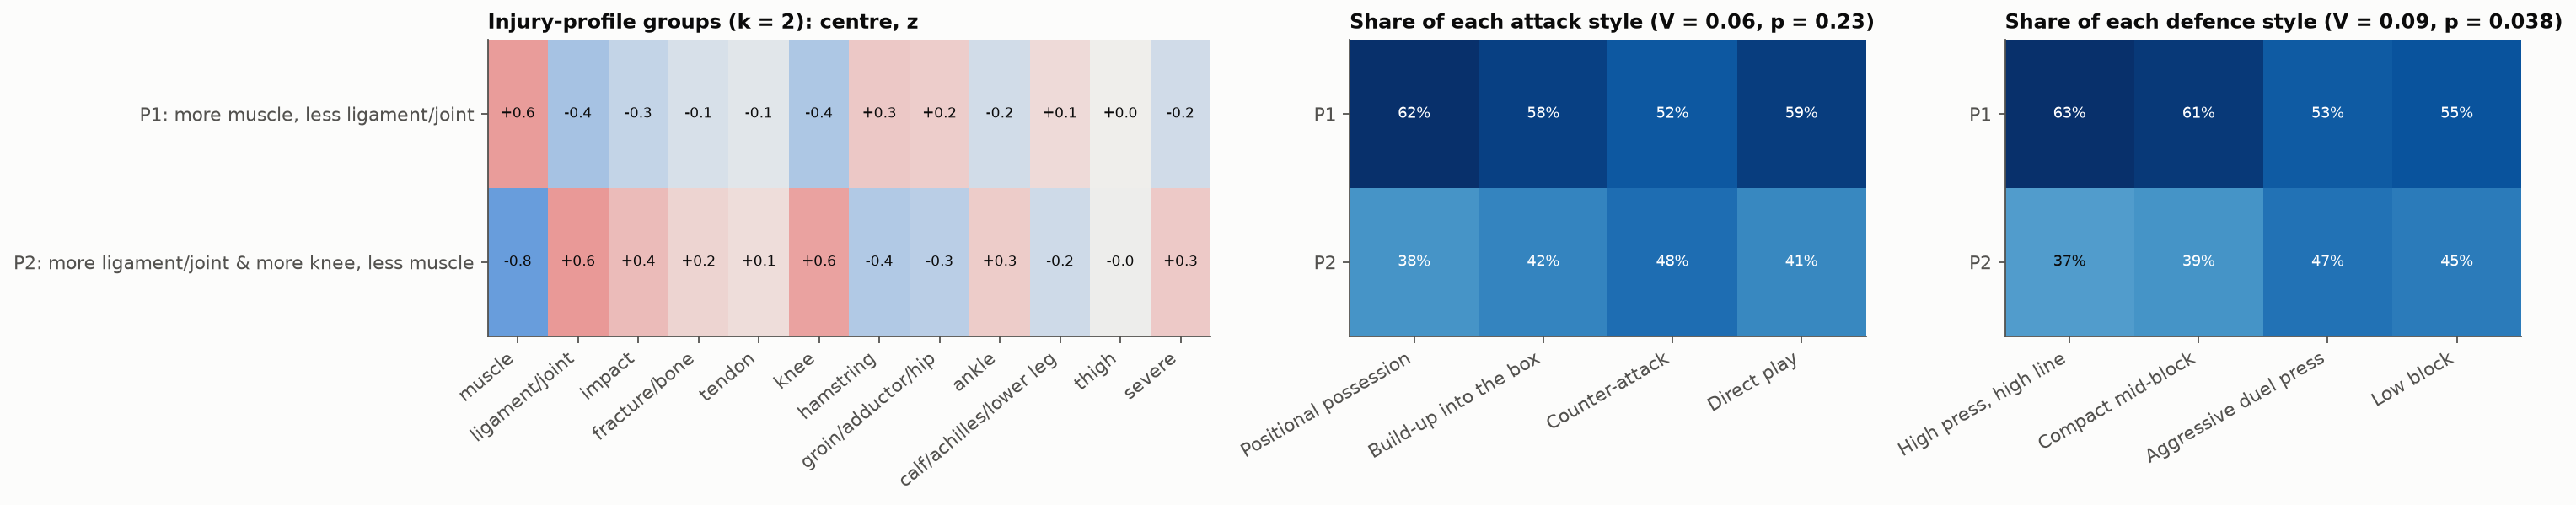

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(19, 3.2 + 0.35 * K), gridspec_kw={"width_ratios": [1.4, 1, 1]})
ax = axes[0]
ax.imshow(centres.to_numpy(), cmap=DIVERGING, vmin=-1.2, vmax=1.2, aspect="auto")
ax.set_xticks(range(len(centres.columns)), centres.columns, rotation=40, ha="right")
ax.set_yticks(range(len(centres)), centres.index)
for (i, j), v in np.ndenumerate(centres.to_numpy()):
    ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=7.5)
ax.set_title(f"Injury-profile groups (k = {K}): centre, z", loc="left")
for ax, (ph, c) in zip(axes[1:], cross.items()):
    ax.imshow(c.to_numpy(), cmap="Blues", vmin=0, vmax=c.to_numpy().max(), aspect="auto")
    ax.set_xticks(range(len(c.columns)), c.columns, rotation=30, ha="right")
    ax.set_yticks(range(len(c)), [n.split(":")[0] for n in c.index])
    for (i, j), v in np.ndenumerate(c.to_numpy()):
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8, color="white" if v > 0.6 * c.to_numpy().max() else INK)
    v, p = assoc.loc[f"{ph} style", ["Cramér's V", "permutation p"]]
    ax.set_title(f"Share of each {ph} style (V = {v:.2f}, p = {p:.2g})", loc="left")
fig.tight_layout()
cluster_fig = save(fig, "06_profile_clusters.png")

## Step 8. Report

In [12]:
TABLES = OUT_DIR / "tables"
TABLES.mkdir(exist_ok=True)
omnibus.to_csv(TABLES / "omnibus.csv", index=False)
profiles.to_csv(TABLES / "profile_ratios.csv", index=False)
k_table.to_csv(TABLES / "profile_k.csv")
centres.to_csv(TABLES / "profile_centres.csv")
assoc.to_csv(TABLES / "profile_association.csv")
for ph, c in cross.items():
    c.to_csv(TABLES / f"profile_by_{ph}_style.csv")
prof.reset_index().to_parquet(OUT_DIR / "team_season_profiles.parquet", index=False)

show = ["phase", "style", "family", "category", "observed", "expected", "ratio", "low", "high", "q (BH)",
        "ratio + position", "ratio + position + strength", "adjusted low", "adjusted high", "robust"]
text = ["# Phase 6: Injury profiles per style", "",
        f"Generated {date.today().isoformat()} by `notebooks/06_injury_profiles.ipynb`, where each step is shown with its checks.", "",
        "## Key numbers", "",
        f"- {len(inj):,} injuries > 7 days in {len(TEAM):,} team-seasons; {int(known_type.sum()):,} with a known type, "
        f"{int(known_loc.sum()):,} with a known location.",
        f"- **RQ-P1 (does the mix differ by style?):** "
        + "; ".join(f"{r.phase} × {r.family}: p = {r.p:.3g}, V = {r.V:.3f}" for r in omnibus.itertuples()) + ".",
        f"- **RQ-P2 (which patterns?):** {len(profiles)} style × category tests; {int(profiles.finding.sum())} findings at q < 0.05, "
        f"{int((profiles.finding & profiles.robust).sum())} of them robust to position and team strength.",
        f"- **RQ-P3 (injury-profile groups):** usable k: {', '.join(map(str, usable.index)) or 'none'}; chosen k = {K}; "
        f"silhouette {k_table.loc[K, 'silhouette']:.3f} vs null 95th percentile {k_table.loc[K, 'null silhouette (95th pct)']:.3f}; "
        f"agreement with attacking style V = {assoc.loc['attack style', 'Cramér' + chr(39) + 's V']:.3f} (p = {assoc.loc['attack style', 'permutation p']:.3g}; "
        f"within strength {assoc.loc['attack style', 'permutation p (within strength)']:.3g}), "
        f"defensive style V = {assoc.loc['defence style', 'Cramér' + chr(39) + 's V']:.3f} (p = {assoc.loc['defence style', 'permutation p']:.3g}; "
        f"within strength {assoc.loc['defence style', 'permutation p (within strength)']:.3g}), "
        f"strength V = {assoc.loc['strength', 'Cramér' + chr(39) + 's V']:.3f}, "
        f"league V = {assoc.loc['league', 'Cramér' + chr(39) + 's V']:.3f}.",
        "", "## 1. Categories", "",
        md_table(pd.concat({"injuries": Y.sum().astype(int), "share of its denominator": (Y.sum() / D.sum()).round(3)}, axis=1)), "",
        "## 2. Does the mix differ by style? (omnibus permutation tests)", "", md_table(omnibus.round(4), index=False), "",
        "## 3. Profile ratios (observed ÷ expected from league × season; 95% CI over clubs)", "",
        f"![Profile ratios](figures/{profile_fig})", "",
        "### Findings (Benjamini–Hochberg q < 0.05)", "",
        md_table(findings[show].round(3), index=False) if len(findings) else "None.", "",
        "### All tests", "", md_table(profiles[show + ["p"]].round(3), index=False), "",
        "## 4. Clustering team-seasons by injury profile", "",
        f"{int(keep.sum())} team-seasons with at least {MIN_INJ} injuries; features: smoothed deviation from the league-season mix "
        f"(α = {ALPHA}), standardised.", "", md_table(k_table.round(3)), "", f"![k](figures/{k_fig})", "",
        "Group centres (z):", "", md_table(centres.round(2)), "",
        md_table(prof.profile.value_counts().rename("team-seasons").to_frame().rename_axis("group")), "",
        "## 5. Do the groups line up with styles?", "", md_table(assoc.round(4)), ""]
for ph, c in cross.items():
    text += [f"Share of each {ph} style in each group (%):", "", md_table((100 * c).round(0).rename_axis("group")), ""]
text += [f"![Groups](figures/{cluster_fig})", "", "## 6. Outputs", "",
         f"- `data/{PHASE}/tables/`: omnibus tests, profile ratios, k selection, group centres, associations.",
         f"- `data/{PHASE}/team_season_profiles.parquet`: each team-season's injury-profile group.", ""]
(REPORTS_DIR / "06_injury_profiles.md").write_text("\n".join(text), encoding="utf-8")
print("wrote", REPORTS_DIR / "06_injury_profiles.md")

wrote /Users/mohammadshweiki/Downloads/coding-projects/football-injuries/reports/06_injury_profiles.md
